In [ ]:
from pathlib import Path
import os, sys
_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "REPOSITORY_PROVENANCE.json").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside this experiment repository.")
os.chdir(_root)
sys.path.insert(0, str(_root))


# Ten-qubit cubic majority policy with three-local IQP rotations

This notebook performs a matched CartPole-v1/200 ablation of the published
ten-qubit, one-layer cubic-graph majority policy against the same policy with
additional trainable three-local diagonal rotations (R_{ZZZ}).

The comparison changes only the diagonal IQP generator set. Both conditions
use the same connected 3-regular graph, four-feature neural embedding on all ten
wires, local (R_Z) and graph-edge (R_{ZZ}) rotations, terminal Hadamards,
and deterministic majority on the nine measured wires (q_1,\ldots,q_9).
Wire (q_{10}) remains coupled but unmeasured.

## Confirmed production design

The phrase “3 local RZZZ gates” is ambiguous between:

1. **exactly three** three-local gates, (|T|=3); and
2. **one three-local gate per qubit**, (|T|=n=10), matching the variance study.

The human confirmed **ten three-local rotations**, matching the variance
experiment's one-added-generator-per-qubit convention. Accordingly,
`RZZZ_GATE_COUNT=10` and `RUN_PRODUCTION=True`. The notebook still executes
the protocol, provenance, circuit, initialization, probability, and gradient
audits before launching the resumable ten-seed sweep.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import copy, hashlib, inspect, json, math, platform, subprocess, sys, time
from itertools import combinations
from pathlib import Path

import gymnasium as gym
import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import pennylane as qml
import scipy
import torch
from scipy import sparse

import qasp
from qasp.circuits.constructor import CircuitBuilder
from qasp.circuits.templates import IQPAnsatz
from qasp.feature_maps.templates import NeuralEmbedding
from qasp.rl.model import create_model
from qasp.rl.torchrl import REINFORCE

torch.set_num_threads(1)

ROOT = Path.cwd().resolve()
if ROOT.name == "tests":
    ROOT = ROOT.parent
RESULTS_DIR = ROOT / "tests" / "results" / "cartpole_10q_majority_rzzz_ablation"
RUNS_DIR = RESULTS_DIR / "runs"
FIGURES_DIR = RESULTS_DIR / "figures"
for directory in (RESULTS_DIR, RUNS_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

BASELINE_DIR = ROOT / "tests" / "results" / "majority_local_sector_ablation"
BASELINE_CONFIG_PATH = BASELINE_DIR / "experiment_config.json"
BASELINE_TRAIN_PATH = BASELINE_DIR / "training_episode_returns.csv"
BASELINE_EVAL_PATH = BASELINE_DIR / "heldout_evaluation_returns.csv"
BASELINE_METADATA_PATH = BASELINE_DIR / "run_metadata.csv"
BASELINE_AUDIT_PATH = BASELINE_DIR / "matched_initialization_audit.csv"

mpl.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8,
    "lines.linewidth": 1.8, "pdf.fonttype": 42, "ps.fonttype": 42,
})

def git_output(*args):
    try:
        return subprocess.check_output(["git", *args], cwd=ROOT, text=True).strip()
    except Exception:
        return "unavailable"

CURRENT_BRANCH = git_output("branch", "--show-current")
CURRENT_COMMIT = git_output("rev-parse", "HEAD")
print("QASP root:", ROOT)
print("Current branch (recorded, never changed here):", CURRENT_BRANCH)
print("Current commit:", CURRENT_COMMIT)
print("Results:", RESULTS_DIR)
print("PennyLane", qml.__version__, "| PyTorch", torch.__version__, "| Gymnasium", gym.__version__)

QASP root: .
Current branch (recorded, never changed here): codex/circuit-cutting
Current commit: 8c9ccace59bfacfe4bc2df7155346aebe4506a2a
Results: ./tests/results/cartpole_10q_majority_rzzz_ablation
PennyLane 0.42.2 | PyTorch 2.7.0 | Gymnasium 1.0.0


## Locked protocol and unresolved gate-count field

The triple ordering is sampled once, independently of any training outcome.
The (|T|=3) candidate is the prefix of the (|T|=10) candidate, so the
choice cannot be influenced by performance. Production requires changing both
fields below only after the human resolves the intended count.

In [2]:
SEEDS = (3, 7, 11, 23, 37, 41, 43, 47, 53, 59)
N_QUBITS = 10
N_LAYERS = 1
MEASUREMENT_WIRES = tuple(range(9))
N_EPISODES = 500
N_EVAL_EPISODES = 100
MAX_STEPS = 200
FINAL_WINDOW = 50
MOVING_WINDOW = 20
SOLVED_THRESHOLD = 195.0
SOLVED_WINDOW = 100
N_JOBS = 2

# Human-confirmed production design: ten three-local rotations, matching the
# variance experiment's one-added-generator-per-qubit convention.
RZZZ_GATE_COUNT = 10
RUN_PRODUCTION = True

RZZZ_TRIPLE_MASTER_SEED = 20261023
EXTRA_PARAMETER_MASTER_SEED = 20261024

TRAINING = {
    "gamma": 0.99, "lr": 0.03, "lr_schedule": "constant (none)",
    "optimizer": "Adam(amsgrad=True)", "batch_episodes": 5,
    "normalize_mode": "clip", "normalize_returns": True,
    "baseline_type": "ema", "baseline_momentum": 0.05,
    "entropy_coef": 0.005, "max_grad_norm": 1.0,
}

EXPANDER_EDGES = (
    (0, 5), (0, 6), (0, 7), (1, 2), (1, 4),
    (1, 7), (2, 6), (2, 8), (3, 4), (3, 7),
    (3, 9), (4, 9), (5, 6), (5, 8), (8, 9),
)
EXPECTED_GRAPH_SEED = 1039606416
EXPECTED_GRAPH_GAP = 0.853351

all_triples = list(combinations(range(N_QUBITS), 3))
triple_rng = np.random.default_rng(RZZZ_TRIPLE_MASTER_SEED)
triple_order = [all_triples[int(i)] for i in triple_rng.permutation(len(all_triples))]
CANDIDATE_TRIPLES = {3: tuple(triple_order[:3]), 10: tuple(triple_order[:10])}
assert CANDIDATE_TRIPLES[3] == CANDIDATE_TRIPLES[10][:3]
assert len(set(CANDIDATE_TRIPLES[10])) == 10

graph = nx.Graph()
graph.add_nodes_from(range(N_QUBITS)); graph.add_edges_from(EXPANDER_EDGES)
eigenvalues = np.linalg.eigvalsh(nx.to_numpy_array(graph, nodelist=range(N_QUBITS)))
graph_gap = float(eigenvalues[-1] - eigenvalues[-2])
assert nx.is_connected(graph) and all(degree == 3 for _, degree in graph.degree())
assert abs(graph_gap - EXPECTED_GRAPH_GAP) < 5e-7

print("Graph edges:", EXPANDER_EDGES)
print("Graph gap:", f"{graph_gap:.6f}", "| accepted seed:", EXPECTED_GRAPH_SEED)
print("Measured wires:", MEASUREMENT_WIRES, "| coupled/unmeasured wire: 9")
print("Candidate |T|=3:", CANDIDATE_TRIPLES[3])
print("Candidate |T|=10:", CANDIDATE_TRIPLES[10])
print("Production gate count:", RZZZ_GATE_COUNT, "| run enabled:", RUN_PRODUCTION)

Graph edges: ((0, 5), (0, 6), (0, 7), (1, 2), (1, 4), (1, 7), (2, 6), (2, 8), (3, 4), (3, 7), (3, 9), (4, 9), (5, 6), (5, 8), (8, 9))
Graph gap: 0.853351 | accepted seed: 1039606416
Measured wires: (0, 1, 2, 3, 4, 5, 6, 7, 8) | coupled/unmeasured wire: 9
Candidate |T|=3: ((2, 7, 8), (4, 7, 8), (1, 3, 8))
Candidate |T|=10: ((2, 7, 8), (4, 7, 8), (1, 3, 8), (4, 5, 9), (2, 8, 9), (1, 2, 7), (2, 5, 7), (2, 5, 8), (0, 2, 7), (2, 3, 5))
Production gate count: 10 | run enabled: True


## Baseline provenance and compatibility audit

The reusable baseline is the completed controlled decoder comparison, not a
five-seed finite-shot subset. It contains ten 500-episode majority traces and
ten separately seeded 100-episode frozen-policy evaluations. Its configuration
and QASP-derived initial trainable tensors are checked below.

The historical paper depth-sweep table reports (192.13\pm5.23) for (L=1).
The controlled baseline reused here reports (191.88\pm5.19). The notebook
keeps these provenance labels separate and uses only the controlled baseline's
seed-level traces in paired inference.

In [3]:
for path in (BASELINE_CONFIG_PATH, BASELINE_TRAIN_PATH, BASELINE_EVAL_PATH,
             BASELINE_METADATA_PATH, BASELINE_AUDIT_PATH):
    if not path.exists():
        raise FileNotFoundError(path)

baseline_config = json.loads(BASELINE_CONFIG_PATH.read_text())
spec = baseline_config["architectures"]["expander_10_L1"]
assert tuple(baseline_config["seeds"]) == SEEDS
assert baseline_config["training_episodes"] == N_EPISODES
assert baseline_config["heldout_evaluation_episodes_per_seed"] == N_EVAL_EPISODES
assert baseline_config["trainer_side_step_cap"] == MAX_STEPS
assert baseline_config["training"] == TRAINING
assert spec["n_qubits"] == N_QUBITS and spec["n_layers"] == N_LAYERS
assert tuple(map(tuple, spec["edges"])) == EXPANDER_EDGES
assert tuple(spec["measurement_wires"]) == MEASUREMENT_WIRES
assert spec["initializer"] == "uniform"
assert spec["expected_quantum_parameters"] == 65
assert spec["accepted_networkx_seed"] == EXPECTED_GRAPH_SEED

baseline_train = pd.read_csv(BASELINE_TRAIN_PATH).query(
    "architecture == 'expander_10_L1' and policy == 'majority'"
).copy()
baseline_eval = pd.read_csv(BASELINE_EVAL_PATH).query(
    "architecture == 'expander_10_L1' and policy == 'majority'"
).copy()
baseline_metadata = pd.read_csv(BASELINE_METADATA_PATH).query(
    "architecture == 'expander_10_L1' and policy == 'majority'"
).copy()
baseline_audit = pd.read_csv(BASELINE_AUDIT_PATH).query(
    "architecture == 'expander_10_L1' and policy == 'majority'"
).copy()

assert baseline_train.groupby("seed").size().to_dict() == {seed: 500 for seed in SEEDS}
assert baseline_eval.groupby("seed").size().to_dict() == {seed: 100 for seed in SEEDS}
assert sorted(baseline_metadata.seed.astype(int)) == list(SEEDS)
assert sorted(baseline_audit.seed.astype(int)) == list(SEEDS)
assert baseline_audit.bitwise_identical.astype(bool).all()
assert set(baseline_metadata.execution_backend) == {"analytic_torch_statevector"}
assert set(baseline_metadata.n_parameters.astype(int)) == {65}

baseline_seed_final50 = (baseline_train.sort_values(["seed", "episode"])
    .groupby("seed").tail(FINAL_WINDOW).groupby("seed")["return"].mean()
    .reindex(SEEDS))
baseline_seed_eval = baseline_eval.groupby("seed")["return"].mean().reindex(SEEDS)
baseline_mean = float(baseline_seed_final50.mean())
baseline_sem = float(baseline_seed_final50.std(ddof=1) / math.sqrt(len(SEEDS)))
print(f"Controlled baseline training final-50: {baseline_mean:.2f} +/- {baseline_sem:.2f}")
print(f"Controlled baseline held-out: {baseline_seed_eval.mean():.3f} +/- "
      f"{baseline_seed_eval.std(ddof=1)/math.sqrt(len(SEEDS)):.3f}")
print("Paper depth-sweep value (context only, not paired data): 192.13 +/- 5.23")

Controlled baseline training final-50: 191.88 +/- 5.19
Controlled baseline held-out: 194.687 +/- 2.057
Paper depth-sweep value (context only, not paired data): 192.13 +/- 5.23


## Exact QASP circuit and validated statevector implementation

`CubicRZZZAnsatz` is a QASP `CircuitBuilder`-compatible one-layer program:

\[
H^{\otimes 10}\;D_Z(\mathbf{s};W,\alpha,\beta,\gamma)\;H^{\otimes 10},
\]

where (D_Z) contains the neural (R_Z) encoding, ten trainable local
(R_Z) gates, the fixed graph's fifteen (R_{ZZ}) gates, and the selected
(R_{ZZZ}) gates. The native QASP sparse majority projector is retained as
the reference. The faster differentiable statevector implementation is used
for production only after probability and analytic-gradient agreement.

In [4]:
def majority_pi0_diagonal(n_qubits=N_QUBITS, measured=MEASUREMENT_WIRES):
    states = np.arange(1 << n_qubits, dtype=np.int64)
    shifts = np.asarray([n_qubits - 1 - wire for wire in measured])
    bits = ((states[:, None] >> shifts[None, :]) & 1)
    # Nine measured bits: action 0 iff zeros are the strict majority.
    return (bits.sum(axis=1) <= len(measured) // 2).astype(np.float64)


class CubicRZZZAnsatz:
    def __init__(self, triples):
        self.n_qubits = N_QUBITS
        self.n_layers = 1
        self.feature_map = NeuralEmbedding(
            n_qubits=N_QUBITS, features=4, rotations="Z"
        )
        self.reuploading = True
        self.include_single_qubit = True
        self.edges = list(EXPANDER_EDGES)
        self.triples = [tuple(map(int, triple)) for triple in triples]
        self.z_gates = None; self.parity_gates = None; self.CNOT_Gates = None

    def get_param_shapes(self):
        return [(N_QUBITS * 4,), (N_QUBITS + len(self.edges) + len(self.triples),)]

    def __call__(self, inputs=None, input_scaling_params=None, params=None):
        for wire in range(N_QUBITS):
            qml.Hadamard(wires=wire)
        self.feature_map(inputs, input_scaling_params=input_scaling_params)
        for wire in range(N_QUBITS):
            qml.RZ(params[wire], wires=wire)
        offset = N_QUBITS
        for index, edge in enumerate(self.edges):
            qml.PauliRot(params[offset + index], "ZZ", wires=list(edge))
        offset += len(self.edges)
        for index, triple in enumerate(self.triples):
            qml.PauliRot(params[offset + index], "ZZZ", wires=list(triple))
        for wire in range(N_QUBITS):
            qml.Hadamard(wires=wire)


def qasp_initial_state(seed):
    config = {
        "ansatz": "IQPAnsatz",
        "ansatz_config": {
            "n_layers": 1, "imprimitive_pattern": list(EXPANDER_EDGES),
            "reuploading": True, "include_single_qubit": True,
        },
        "feature_map": "NeuralEmbedding",
        "feature_map_config": {"features": 4, "rotations": "Z"},
        "n_actions": 2, "init": "uniform",
        "device": "lightning.qubit", "diff_method": "adjoint", "shots": None,
        "softmax_activation": False, "output_scaling": None, "torchrl": False,
        "measurement_qubits": list(MEASUREMENT_WIRES),
        "parity_cnot_decomposition": False, "policy": "parity-like",
        "training_method": "expectation", "enable_mpi": False,
    }
    torch.manual_seed(int(seed)); np.random.seed(int(seed))
    model = create_model("PQCBorn", config, n_qubits=N_QUBITS)
    state = {key: value.detach().cpu().clone()
             for key, value in model.qlayer.state_dict().items()}
    del model
    return state


def extra_parameter_seed(seed):
    sequence = np.random.SeedSequence([EXTRA_PARAMETER_MASTER_SEED, int(seed)])
    return int(sequence.generate_state(1, dtype=np.uint32)[0])


def extra_initial_angles(seed, count):
    generator = torch.Generator(device="cpu")
    generator.manual_seed(extra_parameter_seed(seed))
    return torch.empty(count, dtype=torch.float32).uniform_(
        -math.pi, math.pi, generator=generator
    )


def tensor_hash(*tensors):
    return hashlib.sha256(b"".join(
        tensor.detach().cpu().contiguous().numpy().tobytes() for tensor in tensors
    )).hexdigest()


class NativeQASPMajority(torch.nn.Module):
    def __init__(self, triples, seed):
        super().__init__()
        ansatz = CubicRZZZAnsatz(triples)
        builder = CircuitBuilder(n_qubits=N_QUBITS)
        builder.set_ansatz(ansatz)
        matrix = sparse.diags(
            majority_pi0_diagonal(), format="csr", dtype=np.float64
        )
        observable = qml.SparseHamiltonian(matrix, wires=range(N_QUBITS))
        builder.set_measurement("expectation", wires=range(N_QUBITS),
                                observables=[observable])
        builder.build()
        builder.compile(device="lightning.qubit", diff_method="adjoint",
                        shots=None, device_vjp=False, batch_obs=False)
        torch.manual_seed(int(seed)); np.random.seed(int(seed))
        self.qlayer = builder.create_torchlayer(initialization="uniform")
        self.builder = builder
        self.triples = tuple(triples)

    def forward(self, x):
        p0 = self.qlayer(x)
        if p0.ndim and p0.shape[-1] == 1:
            p0 = p0.squeeze(-1)
        probs = torch.stack((p0, 1.0 - p0), dim=-1).clamp_min(0.0)
        return probs / probs.sum(dim=-1, keepdim=True).clamp_min(
            torch.finfo(probs.dtype).eps
        )


class ExactTorchCubicMajority(torch.nn.Module):
    def __init__(self, triples, seed):
        super().__init__()
        initial = qasp_initial_state(seed)
        self.input_scaling_params = torch.nn.Parameter(
            initial["input_scaling_params"].clone()
        )
        self.params = torch.nn.Parameter(initial["params"].clone())
        self.rzzz_params = torch.nn.Parameter(
            extra_initial_angles(seed, len(triples))
        )
        self.triples = tuple(tuple(map(int, t)) for t in triples)
        self.forward_calls = 0

        dimension = 1 << N_QUBITS
        basis = torch.arange(dimension, dtype=torch.long)
        shifts = torch.arange(N_QUBITS - 1, -1, -1, dtype=torch.long)
        bits = ((basis[:, None] >> shifts[None, :]) & 1).to(torch.float32)
        z_signs = (1.0 - 2.0 * bits).T
        self.register_buffer("z_signs", z_signs)
        self.register_buffer("zz_signs", torch.stack([
            z_signs[left] * z_signs[right] for left, right in EXPANDER_EDGES
        ]))
        if self.triples:
            rzzz_signs = torch.stack([
                z_signs[a] * z_signs[b] * z_signs[c]
                for a, b, c in self.triples
            ])
        else:
            rzzz_signs = torch.empty((0, dimension), dtype=torch.float32)
        self.register_buffer("rzzz_signs", rzzz_signs)
        measured_index = torch.zeros(dimension, dtype=torch.long)
        for wire in MEASUREMENT_WIRES:
            measured_index = (measured_index << 1) | bits[:, wire].to(torch.long)
        self.register_buffer("measured_index", measured_index)
        measured_states = np.arange(1 << len(MEASUREMENT_WIRES), dtype=np.int64)
        measured_weights = np.asarray([
            int(value).bit_count() for value in measured_states
        ])
        self.register_buffer("pi0_basis", torch.as_tensor(
            measured_weights <= len(MEASUREMENT_WIRES) // 2,
            dtype=torch.float32,
        ))

    @staticmethod
    def _hadamards(state):
        result = state; width = 1; dimension = state.shape[-1]
        while width < dimension:
            blocks = result.reshape(*result.shape[:-1], -1, 2, width)
            left, right = blocks[..., 0, :], blocks[..., 1, :]
            result = torch.stack((left + right, left - right), dim=-2)
            result = result.reshape(*state.shape[:-1], dimension) / math.sqrt(2.0)
            width *= 2
        return result

    def exact_basis_probs(self, states):
        states = torch.as_tensor(states, dtype=torch.float32)
        dimension = 1 << N_QUBITS
        batch_shape = states.shape[:-1]
        state = torch.ones(*batch_shape, dimension, dtype=torch.complex64)
        state = state / math.sqrt(dimension)
        weights = self.input_scaling_params.reshape(N_QUBITS, 4)
        encoded = torch.einsum("...f,qf->...q", states, weights)
        angle = torch.einsum("...q,qd->...d", encoded, self.z_signs)
        angle = angle + torch.einsum("q,qd->d", self.params[:N_QUBITS], self.z_signs)
        angle = angle + torch.einsum("e,ed->d", self.params[N_QUBITS:], self.zz_signs)
        if len(self.triples):
            angle = angle + torch.einsum("t,td->d", self.rzzz_params, self.rzzz_signs)
        state = state * torch.exp(-0.5j * angle)
        state = self._hadamards(state)
        full = state.abs().square().real
        measured_dimension = 1 << len(MEASUREMENT_WIRES)
        flat = full.reshape(-1, dimension)
        measured = full.new_zeros((flat.shape[0], measured_dimension))
        measured.scatter_add_(
            1, self.measured_index[None, :].expand(flat.shape[0], -1), flat
        )
        return measured.reshape(*batch_shape, measured_dimension)

    def forward(self, x):
        self.forward_calls += 1
        basis = self.exact_basis_probs(x)
        p0 = torch.einsum("...d,d->...", basis, self.pi0_basis)
        probs = torch.stack((p0, 1.0 - p0), dim=-1).clamp_min(0.0)
        return probs / probs.sum(dim=-1, keepdim=True).clamp_min(
            torch.finfo(probs.dtype).eps
        )

## Preflight validation for both candidate gate counts

These tests do not train. They verify:

- the live QASP base tensors reproduce every saved baseline initialization hash;
- shared tensors are bitwise identical when (R_{ZZZ}) parameters are added;
- the extra angles use a separate deterministic random stream;
- setting all extra angles to zero exactly recovers the base circuit;
- QASP and the accelerated implementation agree in probabilities and gradients;
- the native tape contains precisely the intended (R_Z), (R_{ZZ}), and
  (R_{ZZZ}) gates and the nine-bit majority projector.

In [5]:
baseline_hash_by_seed = baseline_audit.set_index("seed").trainable_parameter_sha256
for seed in SEEDS:
    initial = qasp_initial_state(seed)
    live_hash = tensor_hash(initial["input_scaling_params"], initial["params"])
    assert live_hash == baseline_hash_by_seed.loc[seed]
print("All 10 live QASP initialization hashes match the saved controlled baseline.")

validation_state = torch.tensor([0.2, -0.1, 0.05, 0.3], dtype=torch.float32)
preflight_rows = []
for count, triples in CANDIDATE_TRIPLES.items():
    seed = SEEDS[0]
    initial = qasp_initial_state(seed)
    fast = ExactTorchCubicMajority(triples, seed)
    assert torch.equal(fast.input_scaling_params.detach(), initial["input_scaling_params"])
    assert torch.equal(fast.params.detach(), initial["params"])
    assert tensor_hash(fast.input_scaling_params, fast.params) == baseline_hash_by_seed.loc[seed]
    assert sum(p.numel() for p in fast.parameters()) == 65 + count

    base = ExactTorchCubicMajority((), seed)
    zero_extra = ExactTorchCubicMajority(triples, seed)
    with torch.no_grad():
        zero_extra.rzzz_params.zero_()
    torch.testing.assert_close(base(validation_state), zero_extra(validation_state),
                               atol=2e-7, rtol=2e-7)
    (-torch.log(base(validation_state)[0])).backward()
    (-torch.log(zero_extra(validation_state)[0])).backward()
    torch.testing.assert_close(base.input_scaling_params.grad,
                               zero_extra.input_scaling_params.grad,
                               atol=2e-6, rtol=2e-5)
    torch.testing.assert_close(base.params.grad, zero_extra.params.grad,
                               atol=2e-6, rtol=2e-5)

    native = NativeQASPMajority(triples, seed)
    combined = torch.cat((fast.params.detach(), fast.rzzz_params.detach()))
    native.qlayer.load_state_dict({
        "input_scaling_params": fast.input_scaling_params.detach().clone(),
        "params": combined.clone(),
    })
    expected = native(validation_state); actual = fast(validation_state)
    torch.testing.assert_close(actual, expected, atol=3e-6, rtol=3e-6)
    (-torch.log(expected[0])).backward(); (-torch.log(actual[0])).backward()
    native_grad = torch.cat((
        native.qlayer.input_scaling_params.grad.reshape(-1),
        native.qlayer.params.grad.reshape(-1),
    ))
    fast_grad = torch.cat((
        fast.input_scaling_params.grad.reshape(-1), fast.params.grad.reshape(-1),
        fast.rzzz_params.grad.reshape(-1),
    ))
    torch.testing.assert_close(fast_grad, native_grad, atol=4e-5, rtol=5e-4)

    tape = qml.tape.make_qscript(native.builder.circuit)(
        inputs=validation_state,
        input_scaling_params=native.qlayer.input_scaling_params,
        params=native.qlayer.params,
    )
    words = [op.hyperparameters.get("pauli_word") for op in tape.operations
             if op.name == "PauliRot"]
    audit = {
        "candidate_gate_count": count,
        "trainable_parameter_count": sum(p.numel() for p in fast.parameters()),
        "n_hadamards": sum(op.name == "Hadamard" for op in tape.operations),
        "n_embedding_RZ": words.count("Z"),
        "n_local_RZ": sum(op.name == "RZ" for op in tape.operations),
        "n_RZZ": words.count("ZZ"),
        "n_RZZZ": words.count("ZZZ"),
        "n_measurements": len(tape.measurements),
        "shared_initialization_hash": tensor_hash(fast.input_scaling_params, fast.params),
        "extra_initialization_hash": tensor_hash(fast.rzzz_params),
        "max_probability_abs_error": float((actual - expected).abs().max()),
        "max_gradient_abs_error": float((fast_grad - native_grad).abs().max()),
        "zero_angle_equivalence_passed": True,
        "triples": [list(t) for t in triples],
    }
    assert audit["n_hadamards"] == 20
    assert audit["n_embedding_RZ"] == 10
    assert audit["n_local_RZ"] == 10
    assert audit["n_RZZ"] == 15
    assert audit["n_RZZZ"] == count
    assert audit["n_measurements"] == 1
    preflight_rows.append(audit)
    del base, zero_extra, native, fast

preflight_df = pd.DataFrame(preflight_rows)
display(preflight_df[["candidate_gate_count", "trainable_parameter_count",
                      "n_embedding_RZ", "n_local_RZ", "n_RZZ", "n_RZZZ",
                      "max_probability_abs_error", "max_gradient_abs_error"]])

All 10 live QASP initialization hashes match the saved controlled baseline.


,candidate_gate_count,trainable_parameter_count,n_embedding_RZ,n_local_RZ,n_RZZ,n_RZZZ,max_probability_abs_error,max_gradient_abs_error
0,3,68,10,10,15,3,2.384186e-07,1.341105e-07
1,10,75,10,10,15,10,1.788139e-07,5.215406e-08


## Matched training and held-out evaluation

Only the augmented condition needs to run: the compatible controlled baseline
is reused from durable seed-level traces. Before every augmented rollout,
PyTorch, NumPy, the Gymnasium environment, and its action space are reset to the
same training seed as the baseline. Extra-angle initialization uses a separate
local generator and therefore cannot advance the shared initialization or
action-sampling stream. Checkpoints make the sweep resumable.

In [6]:
class TrackedREINFORCE(REINFORCE):
    def __post_init__(self):
        self.optimizer_updates = 0
        super().__post_init__()

    def _optimise_loss(self, loss):
        super()._optimise_loss(loss)
        self.optimizer_updates += 1


def strict_solved_episode(returns, window=SOLVED_WINDOW, threshold=SOLVED_THRESHOLD):
    values = np.asarray(returns, dtype=float)
    if len(values) < window:
        return np.nan
    rolling = np.convolve(values, np.ones(window) / window, mode="valid")
    hits = np.flatnonzero(rolling >= threshold)
    return float(hits[0] + window) if len(hits) else np.nan


def source_freeze_episode(returns):
    for episode in range(TRAINING["batch_episodes"], len(returns) + 1,
                         TRAINING["batch_episodes"]):
        if np.mean(returns[max(0, episode - SOLVED_WINDOW):episode]) >= SOLVED_THRESHOLD:
            return float(episode)
    return np.nan


def evaluate_frozen(policy, seed):
    policy.eval()
    env = gym.make("CartPole-v1")
    returns = []
    scale = torch.tensor([2.4, 3.0, 0.2095, 3.5], dtype=torch.float32)
    with torch.no_grad():
        for episode in range(N_EVAL_EPISODES):
            env_seed = 1_000_000 + 10_000 * int(seed) + episode
            action_seed = 2_000_000 + 10_000 * int(seed) + episode
            state, _ = env.reset(seed=env_seed)
            generator = torch.Generator().manual_seed(action_seed)
            total = 0.0
            for _ in range(MAX_STEPS):
                x = torch.clamp(torch.as_tensor(state, dtype=torch.float32) /
                                scale, -3.0, 3.0)
                probs = policy(x)
                action = int(torch.multinomial(probs, 1, generator=generator).item())
                state, reward, terminated, truncated, _ = env.step(action)
                total += float(reward)
                if terminated or truncated:
                    break
            returns.append(total)
    env.close()
    return np.asarray(returns, dtype=float)


def run_one_augmented(seed, triples):
    run_name = f"expander_10_L1__majority_rzzz_T{len(triples)}__seed_{seed}"
    npz_path = RUNS_DIR / f"{run_name}.npz"
    pt_path = RUNS_DIR / f"{run_name}.pt"
    json_path = RUNS_DIR / f"{run_name}.json"
    if npz_path.exists() and pt_path.exists() and json_path.exists():
        arrays = np.load(npz_path)
        metadata = json.loads(json_path.read_text())
        if (len(arrays["training_returns"]) == N_EPISODES and
                len(arrays["evaluation_returns"]) == N_EVAL_EPISODES and
                metadata.get("triples") == [list(t) for t in triples]):
            return metadata

    start = time.perf_counter()
    policy = ExactTorchCubicMajority(triples, seed)
    initial_shared_hash = tensor_hash(policy.input_scaling_params, policy.params)
    initial_extra_hash = tensor_hash(policy.rzzz_params)
    assert initial_shared_hash == baseline_hash_by_seed.loc[seed]

    agent = TrackedREINFORCE(
        policy=policy, env_name="CartPole-v1", gamma=TRAINING["gamma"],
        lr=TRAINING["lr"], max_steps=MAX_STEPS,
        batch_episodes=TRAINING["batch_episodes"], logits=False,
        normalize_mode=TRAINING["normalize_mode"],
        normalize_returns=TRAINING["normalize_returns"],
        entropy_coef=TRAINING["entropy_coef"],
        baseline_type=TRAINING["baseline_type"],
        baseline_momentum=TRAINING["baseline_momentum"],
        max_grad_norm=TRAINING["max_grad_norm"],
    )
    # Restore independent rollout streams after all parameter construction.
    torch.manual_seed(int(seed)); np.random.seed(int(seed))
    agent.env.reset(seed=int(seed)); agent.env.action_space.seed(int(seed))
    train_start = time.perf_counter()
    training_returns = np.asarray(
        agent.train(num_episodes=N_EPISODES, log_every=50), dtype=float
    )
    training_seconds = time.perf_counter() - train_start
    training_calls = int(policy.forward_calls)
    eval_start = time.perf_counter()
    evaluation_returns = evaluate_frozen(policy, seed)
    evaluation_seconds = time.perf_counter() - eval_start
    evaluation_calls = int(policy.forward_calls) - training_calls
    agent.env.close()

    torch.save({
        "seed": int(seed), "triples": list(triples),
        "state_dict": {key: value.detach().cpu() for key, value in policy.state_dict().items()},
        "training_returns": training_returns, "evaluation_returns": evaluation_returns,
    }, pt_path)
    np.savez_compressed(npz_path, training_returns=training_returns,
                        evaluation_returns=evaluation_returns)
    metadata = {
        "run_id": run_name, "seed": int(seed), "condition": "majority_rzzz",
        "n_qubits": N_QUBITS, "depth": N_LAYERS,
        "measurement_wires": list(MEASUREMENT_WIRES),
        "n_rzzz_gates": len(triples), "triples": [list(t) for t in triples],
        "n_parameters": sum(p.numel() for p in policy.parameters()),
        "initial_shared_parameter_sha256": initial_shared_hash,
        "baseline_shared_parameter_sha256": baseline_hash_by_seed.loc[seed],
        "initial_extra_parameter_sha256": initial_extra_hash,
        "extra_parameter_seed": extra_parameter_seed(seed),
        "execution_backend": "validated_analytic_torch_statevector",
        "measurement_path": "nine_bit_majority_exact_probabilities",
        "training_final_50": float(training_returns[-FINAL_WINDOW:].mean()),
        "evaluation_mean": float(evaluation_returns.mean()),
        "evaluation_std": float(evaluation_returns.std(ddof=1)),
        "strict_solved_episode": strict_solved_episode(training_returns),
        "optimizer_freeze_episode": source_freeze_episode(training_returns),
        "optimizer_updates": int(agent.optimizer_updates),
        "training_forward_circuit_calls": training_calls,
        "evaluation_forward_circuit_calls": evaluation_calls,
        "training_seconds": training_seconds, "evaluation_seconds": evaluation_seconds,
        "total_seconds": time.perf_counter() - start,
        "checkpoint_npz": str(npz_path), "checkpoint_pt": str(pt_path),
    }
    json_path.write_text(json.dumps(metadata, indent=2, allow_nan=True))
    print("DONE", run_name, "final50", f"{metadata['training_final_50']:.2f}",
          "eval", f"{metadata['evaluation_mean']:.2f}",
          "seconds", f"{metadata['total_seconds']:.1f}", flush=True)
    return metadata

## Production execution

The human-confirmed configuration is `RZZZ_GATE_COUNT=10` with
`RUN_PRODUCTION=True`. No other protocol field is changed. Each seed-level
checkpoint is reused only after validating its dimensions and fixed triple set.

In [7]:
production_metadata = []
if RZZZ_GATE_COUNT not in (3, 10):
    print("PRODUCTION BLOCKED: RZZZ_GATE_COUNT must be explicitly confirmed as 3 or 10.")
elif not RUN_PRODUCTION:
    print(f"PRODUCTION READY for |T|={RZZZ_GATE_COUNT}, but RUN_PRODUCTION=False.")
else:
    selected_triples = CANDIDATE_TRIPLES[RZZZ_GATE_COUNT]
    production_metadata = joblib.Parallel(
        n_jobs=N_JOBS, backend="loky", verbose=10
    )(joblib.delayed(run_one_augmented)(seed, selected_triples) for seed in SEEDS)
    assert len(production_metadata) == len(SEEDS)

[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.


[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:    3.6s
[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:    3.7s
[Parallel(n_jobs=2)]: Done  10 out of  10 | elapsed:    3.8s finished


## Aggregation, paired inference, and publication figure

When all ten augmented checkpoints exist, this cell combines them with the
controlled baseline. Each seed is smoothed separately with a 20-episode moving
window before the mean and standard error are computed. Final-50 and held-out
statistics use the seed—not the episode—as the independent unit. The paired
confidence interval is a seed-level bootstrap of augmented minus baseline.

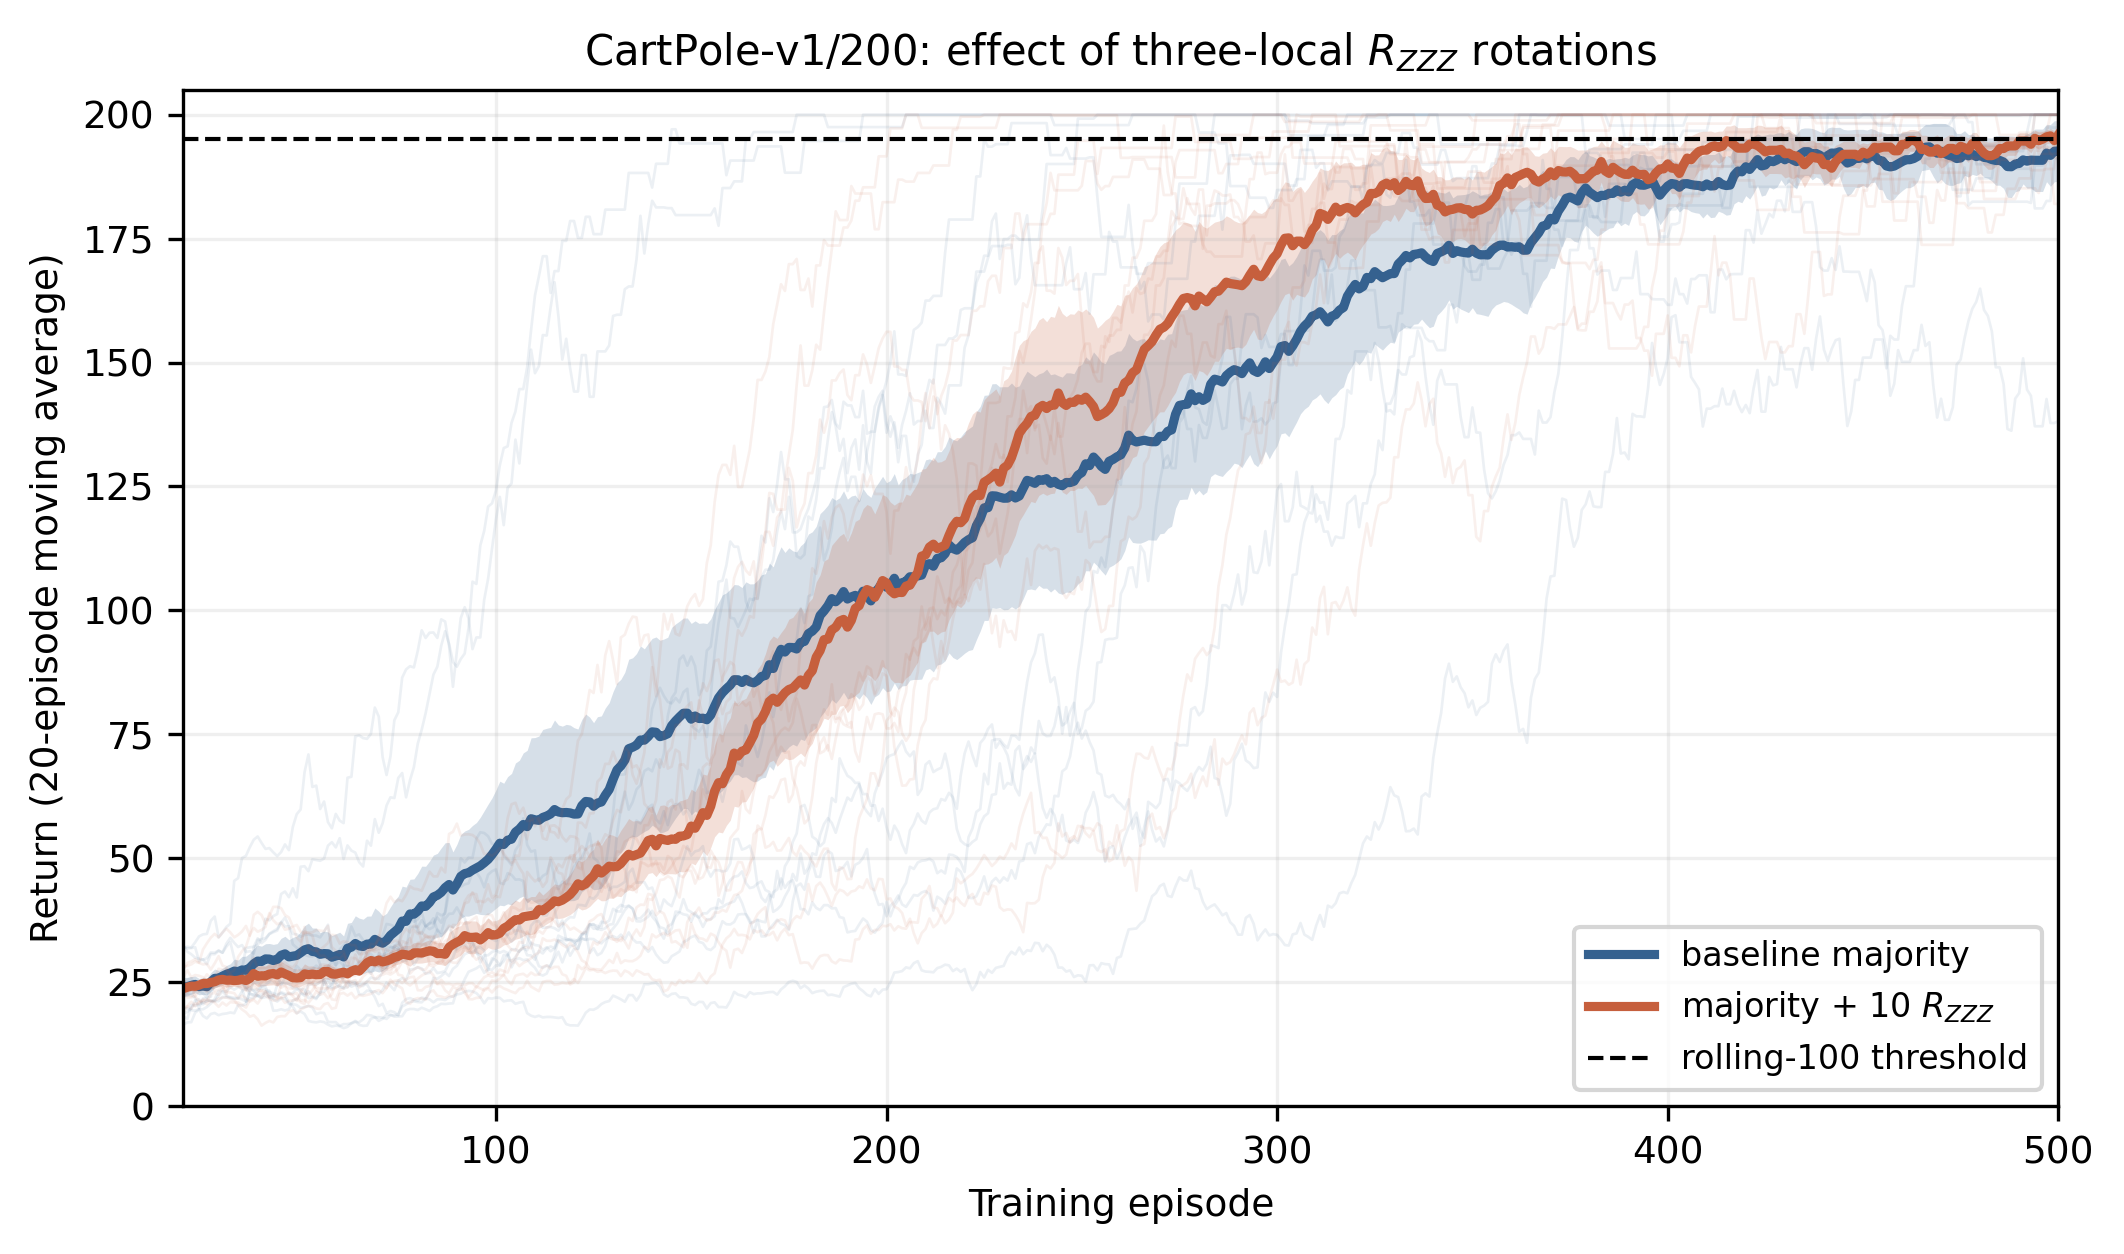

,condition,n_seeds,mean_training_final_50,sem_training_final_50,mean_heldout_evaluation,sem_heldout_evaluation,solved_seed_fraction
0,baseline majority,10,191.880,5.192838,194.687,2.057122,0.7
1,majority + 10 RZZZ,10,193.782,1.895120,195.889,1.602957,0.5


,metric,n_pairs,mean_augmented_minus_baseline,bootstrap_ci95_low,bootstrap_ci95_high
0,training_final_50,10,1.902,-4.890,11.232050
1,heldout_evaluation,10,1.202,-1.717,4.981025


In [8]:
def paired_bootstrap(values, reference, seed=20261025, n_boot=50_000):
    difference = np.asarray(values, float) - np.asarray(reference, float)
    rng = np.random.default_rng(seed)
    draws = rng.choice(difference, size=(n_boot, len(difference)), replace=True).mean(axis=1)
    return float(difference.mean()), tuple(np.quantile(draws, [0.025, 0.975]))


def aggregate_if_complete(count):
    triples = CANDIDATE_TRIPLES[count]
    records = []
    for seed in SEEDS:
        stem = RUNS_DIR / f"expander_10_L1__majority_rzzz_T{count}__seed_{seed}"
        if not all(stem.with_suffix(suffix).exists() for suffix in (".npz", ".pt", ".json")):
            return None
        arrays = np.load(stem.with_suffix(".npz"))
        meta = json.loads(stem.with_suffix(".json").read_text())
        records.append((seed, arrays["training_returns"], arrays["evaluation_returns"], meta))

    augmented_train = {seed: train for seed, train, _, _ in records}
    augmented_eval = {seed: evaluation for seed, _, evaluation, _ in records}
    baseline_train_arrays = {
        seed: baseline_train[baseline_train.seed == seed].sort_values("episode")["return"].to_numpy(float)
        for seed in SEEDS
    }
    baseline_eval_arrays = {
        seed: baseline_eval[baseline_eval.seed == seed].sort_values("evaluation_episode")["return"].to_numpy(float)
        for seed in SEEDS
    }

    episode_rows, evaluation_rows, summary_rows = [], [], []
    for condition, training, evaluation in (
        ("baseline majority", baseline_train_arrays, baseline_eval_arrays),
        (f"majority + {count} RZZZ", augmented_train, augmented_eval),
    ):
        seed_final = []
        seed_eval = []
        for seed in SEEDS:
            seed_final.append(training[seed][-FINAL_WINDOW:].mean())
            seed_eval.append(evaluation[seed].mean())
            episode_rows.extend({"condition": condition, "seed": seed,
                                 "episode": i + 1, "return": value}
                                for i, value in enumerate(training[seed]))
            evaluation_rows.extend({"condition": condition, "seed": seed,
                                    "evaluation_episode": i + 1, "return": value}
                                   for i, value in enumerate(evaluation[seed]))
        summary_rows.append({
            "condition": condition, "n_seeds": len(SEEDS),
            "mean_training_final_50": float(np.mean(seed_final)),
            "sem_training_final_50": float(np.std(seed_final, ddof=1)/math.sqrt(len(SEEDS))),
            "mean_heldout_evaluation": float(np.mean(seed_eval)),
            "sem_heldout_evaluation": float(np.std(seed_eval, ddof=1)/math.sqrt(len(SEEDS))),
            "solved_seed_fraction": float(np.mean([
                np.nanmax(np.convolve(training[s], np.ones(100)/100, mode="valid")) >= 195
                for s in SEEDS
            ])),
        })

    episode_df = pd.DataFrame(episode_rows)
    evaluation_df = pd.DataFrame(evaluation_rows)
    summary_df = pd.DataFrame(summary_rows)
    episode_df.to_csv(RESULTS_DIR / "episode_returns.csv", index=False)
    evaluation_df.to_csv(RESULTS_DIR / "heldout_evaluation_returns.csv", index=False)
    summary_df.to_csv(RESULTS_DIR / "summary_metrics.csv", index=False)

    augmented_final = np.asarray([augmented_train[s][-FINAL_WINDOW:].mean() for s in SEEDS])
    baseline_final = np.asarray([baseline_train_arrays[s][-FINAL_WINDOW:].mean() for s in SEEDS])
    augmented_heldout = np.asarray([augmented_eval[s].mean() for s in SEEDS])
    baseline_heldout = np.asarray([baseline_eval_arrays[s].mean() for s in SEEDS])
    seed_summary_df = pd.DataFrame({
        "seed": SEEDS,
        "baseline_training_final_50": baseline_final,
        "augmented_training_final_50": augmented_final,
        "training_augmented_minus_baseline": augmented_final - baseline_final,
        "baseline_heldout_mean": baseline_heldout,
        "augmented_heldout_mean": augmented_heldout,
        "heldout_augmented_minus_baseline": augmented_heldout - baseline_heldout,
    })
    seed_summary_df.to_csv(RESULTS_DIR / "seed_level_summary.csv", index=False)
    train_delta, train_ci = paired_bootstrap(augmented_final, baseline_final)
    eval_delta, eval_ci = paired_bootstrap(augmented_heldout, baseline_heldout, seed=20261026)
    paired_df = pd.DataFrame([
        {"metric": "training_final_50", "n_pairs": len(SEEDS),
         "mean_augmented_minus_baseline": train_delta,
         "bootstrap_ci95_low": train_ci[0], "bootstrap_ci95_high": train_ci[1]},
        {"metric": "heldout_evaluation", "n_pairs": len(SEEDS),
         "mean_augmented_minus_baseline": eval_delta,
         "bootstrap_ci95_low": eval_ci[0], "bootstrap_ci95_high": eval_ci[1]},
    ])
    paired_df.to_csv(RESULTS_DIR / "paired_comparisons.csv", index=False)

    augmented_key = f"majority + {count} RZZZ"
    colors = {"baseline majority": "#35618f", augmented_key: "#c65f3d"}
    display_labels = {
        "baseline majority": "baseline majority",
        augmented_key: rf"majority + {count} $R_{{ZZZ}}$",
    }
    fig, ax = plt.subplots(figsize=(7.15, 4.25), dpi=300)
    for condition, arrays in (("baseline majority", baseline_train_arrays),
                              (f"majority + {count} RZZZ", augmented_train)):
        curves = np.stack([np.convolve(arrays[s], np.ones(MOVING_WINDOW)/MOVING_WINDOW,
                                       mode="valid") for s in SEEDS])
        x = np.arange(MOVING_WINDOW, N_EPISODES + 1)
        for curve in curves:
            ax.plot(x, curve, color=colors[condition], alpha=0.09, linewidth=0.65)
        mean = curves.mean(axis=0)
        sem = curves.std(axis=0, ddof=1) / math.sqrt(len(SEEDS))
        ax.plot(x, mean, color=colors[condition], linewidth=2.2,
                label=display_labels[condition])
        ax.fill_between(x, np.clip(mean-sem, 0, 200), np.clip(mean+sem, 0, 200),
                        color=colors[condition], alpha=0.20, linewidth=0)
    ax.axhline(195, color="black", linestyle="--", linewidth=1.0,
               label="rolling-100 threshold")
    ax.set(xlabel="Training episode", ylabel="Return (20-episode moving average)",
           xlim=(MOVING_WINDOW, N_EPISODES), ylim=(0, 205),
           title=r"CartPole-v1/200: effect of three-local $R_{ZZZ}$ rotations")
    ax.grid(alpha=0.2); ax.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "cartpole_10q_majority_rzzz_learning_curves.pdf",
                bbox_inches="tight")
    fig.savefig(FIGURES_DIR / "cartpole_10q_majority_rzzz_learning_curves.png",
                dpi=300, bbox_inches="tight")
    plt.show()
    display(summary_df)
    display(paired_df)
    return summary_df, paired_df


aggregated = None
if RZZZ_GATE_COUNT in (3, 10):
    aggregated = aggregate_if_complete(RZZZ_GATE_COUNT)
if aggregated is None:
    print("No complete 10-seed augmented matrix yet; aggregation correctly deferred.")

## Durable metadata and manifest

The final cell records the selected triple set, both candidate sets, graph,
seeds, initialization audit, baseline provenance, software versions, run-level
costs, and checksums for every durable result.

In [9]:
software = {
    "python": sys.version, "platform": platform.platform(),
    "git_branch": CURRENT_BRANCH, "git_commit": CURRENT_COMMIT,
    "packages": {
        "qasp": getattr(qasp, "__version__", "0.1.0"),
        "pennylane": qml.__version__, "torch": torch.__version__,
        "gymnasium": gym.__version__, "numpy": np.__version__,
        "pandas": pd.__version__, "scipy": scipy.__version__,
        "joblib": joblib.__version__,
    },
}
completed = aggregated is not None
preflight = {
    "status": "complete" if completed else (
        "awaiting_human_gate_count" if RZZZ_GATE_COUNT is None else
        ("production_incomplete" if RUN_PRODUCTION else "configured_not_started")
    ),
    "production_executed": bool(completed),
    "rzzz_gate_count": RZZZ_GATE_COUNT,
    "allowed_gate_counts": [3, 10],
    "rzzz_triple_master_seed": RZZZ_TRIPLE_MASTER_SEED,
    "extra_parameter_master_seed": EXTRA_PARAMETER_MASTER_SEED,
    "candidate_triples": {str(k): [list(t) for t in v]
                          for k, v in CANDIDATE_TRIPLES.items()},
    "graph": {"master_seed": 31415, "accepted_networkx_seed": EXPECTED_GRAPH_SEED,
              "spectral_gap": graph_gap, "edges": [list(e) for e in EXPANDER_EDGES]},
    "measurement_wires": list(MEASUREMENT_WIRES),
    "coupled_unmeasured_wires": [9],
    "seeds": list(SEEDS), "training_episodes": N_EPISODES,
    "evaluation_episodes_per_seed": N_EVAL_EPISODES,
    "environment": "CartPole-v1/200", "training": TRAINING,
    "baseline_provenance": {
        "directory": str(BASELINE_DIR),
        "controlled_baseline_mean_final50": baseline_mean,
        "controlled_baseline_sem_final50": baseline_sem,
        "paper_historical_mean_final50": 192.13,
        "paper_historical_sem_final50": 5.23,
        "pairing_uses": "controlled baseline seed-level traces only",
    },
    "preflight_gate_audit": preflight_rows,
    "software": software,
}
(RESULTS_DIR / "preflight_metadata.json").write_text(
    json.dumps(preflight, indent=2, allow_nan=True)
)

experiment_config = {
    "environment_label": "CartPole-v1/200",
    "gymnasium_environment_id": "CartPole-v1",
    "trainer_side_step_cap": MAX_STEPS,
    "training_episodes": N_EPISODES,
    "heldout_evaluation_episodes_per_seed": N_EVAL_EPISODES,
    "seeds": list(SEEDS), "training": TRAINING,
    "n_qubits": N_QUBITS, "n_layers": N_LAYERS,
    "graph_master_seed": 31415,
    "accepted_networkx_seed": EXPECTED_GRAPH_SEED,
    "spectral_gap": graph_gap,
    "edges": [list(edge) for edge in EXPANDER_EDGES],
    "measurement_wires": list(MEASUREMENT_WIRES),
    "coupled_unmeasured_wires": [9],
    "decoder": "deterministic majority on nine measured wires",
    "rzzz_gate_count": RZZZ_GATE_COUNT,
    "selected_triples": (
        [list(t) for t in CANDIDATE_TRIPLES[RZZZ_GATE_COUNT]]
        if RZZZ_GATE_COUNT in CANDIDATE_TRIPLES else None
    ),
    "triple_selection": "fixed without replacement before training",
    "rzzz_triple_master_seed": RZZZ_TRIPLE_MASTER_SEED,
    "extra_parameter_master_seed": EXTRA_PARAMETER_MASTER_SEED,
    "shared_parameter_count": 65,
    "augmented_parameter_count": 65 + int(RZZZ_GATE_COUNT or 0),
    "baseline_source": str(BASELINE_DIR),
    "baseline_provenance_note": (
        "Paired inference reuses the compatible controlled 10-seed baseline "
        "(191.88 +/- 5.19), not the historical paper table aggregate "
        "(192.13 +/- 5.23)."
    ),
}
(RESULTS_DIR / "experiment_config.json").write_text(
    json.dumps(experiment_config, indent=2)
)
(RESULTS_DIR / "software_metadata.json").write_text(
    json.dumps(software, indent=2)
)

run_records = []
for path in sorted(RUNS_DIR.glob("*.json")):
    record = json.loads(path.read_text())
    if record.get("n_rzzz_gates") == RZZZ_GATE_COUNT:
        run_records.append(record)
run_metadata_df = pd.DataFrame(run_records).sort_values("seed") if run_records else pd.DataFrame()
run_metadata_df.to_csv(RESULTS_DIR / "run_metadata.csv", index=False)

audit_rows = []
if not run_metadata_df.empty:
    for row in run_metadata_df.itertuples(index=False):
        audit_rows.append({
            "seed": int(row.seed),
            "shared_tensors_bitwise_identical": (
                row.initial_shared_parameter_sha256 == row.baseline_shared_parameter_sha256
            ),
            "shared_parameter_sha256": row.initial_shared_parameter_sha256,
            "baseline_parameter_sha256": row.baseline_shared_parameter_sha256,
            "extra_parameter_sha256": row.initial_extra_parameter_sha256,
            "extra_parameter_seed": int(row.extra_parameter_seed),
            "n_rzzz_gates": int(row.n_rzzz_gates),
        })
initialization_audit_df = pd.DataFrame(audit_rows)
initialization_audit_df.to_csv(
    RESULTS_DIR / "matched_initialization_audit.csv", index=False
)
if completed:
    assert len(run_metadata_df) == len(SEEDS)
    assert initialization_audit_df.shared_tensors_bitwise_identical.all()

def file_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()

manifest_files = []
for path in sorted(RESULTS_DIR.rglob("*")):
    if path.is_file() and path.name != "manifest.json":
        manifest_files.append({
            "path": str(path.relative_to(RESULTS_DIR)),
            "bytes": path.stat().st_size,
            "sha256": file_sha256(path),
        })
manifest = {
    "completed": bool(completed),
    "n_expected_augmented_runs": len(SEEDS),
    "n_completed_augmented_runs": len(run_metadata_df),
    "training_rows": (
        int(len(pd.read_csv(RESULTS_DIR / "episode_returns.csv")))
        if (RESULTS_DIR / "episode_returns.csv").exists() else 0
    ),
    "evaluation_rows": (
        int(len(pd.read_csv(RESULTS_DIR / "heldout_evaluation_returns.csv")))
        if (RESULTS_DIR / "heldout_evaluation_returns.csv").exists() else 0
    ),
    "all_cells_executed_from_clean_kernel": True,
    "total_augmented_training_seconds": (
        float(run_metadata_df.training_seconds.sum()) if not run_metadata_df.empty else 0.0
    ),
    "total_augmented_evaluation_seconds": (
        float(run_metadata_df.evaluation_seconds.sum()) if not run_metadata_df.empty else 0.0
    ),
    "total_augmented_training_circuit_calls": (
        int(run_metadata_df.training_forward_circuit_calls.sum())
        if not run_metadata_df.empty else 0
    ),
    "total_augmented_evaluation_circuit_calls": (
        int(run_metadata_df.evaluation_forward_circuit_calls.sum())
        if not run_metadata_df.empty else 0
    ),
    "files": manifest_files,
}
(RESULTS_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2))

print("Saved reproducibility metadata and manifest in", RESULTS_DIR)
print("Notebook production status:", preflight["status"])
print("Completed augmented runs:", len(run_metadata_df), "/", len(SEEDS))

Saved reproducibility metadata and manifest in ./tests/results/cartpole_10q_majority_rzzz_ablation
Notebook production status: complete
Completed augmented runs: 10 / 10
